### SPECTRAL ANALYSIS (SIMULATION)

This notebook runs through the generation (or loading) of simulated data, and using that as the data as source to estimate spectral densities.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# can import from specific files
from levisim.core.colours import grey
from levisim.core.constants import π
from levisim.core.units import pm, kiloHz
from levisim.core.utils import load_variable_from_pickle

# can also directly import any of the variables in the entire levisim namespace
from levisim import Simulation, Experiment, SpectralDensityEstimate

if 0:
    # simulating 1e5 samples takes about 10s, and is 2.4MB
    sim = Simulation(num_samples=1e5, save=True)
elif 1:
    # simulating 1e6 samples takes about 90s = 1m30s, and is 24MB
    sim = Simulation(num_samples=1e6, save=True)
else:
    filename = 'default_P4e-03_fbx2e+03_t1e-07_N1e+05'
    filename = 'default_P4e-03_fbx2e+03_t1e-07_N1e+06'
    sim = load_variable_from_pickle(f'pickle/{filename}')

sim.info
sim.trap.info
sim.trap.tweezer.info
sim.trap.bead.info
sim.trap.gas.info

Simulating time step...
0 of 1000000
100000 of 1000000
200000 of 1000000
300000 of 1000000
400000 of 1000000
500000 of 1000000
600000 of 1000000
700000 of 1000000
800000 of 1000000
900000 of 1000000
Done!
Saving <levisim.data.simulation.Simulation object at 0x15d2409d0> to "pickle/default_P4e-03_fbx2e+03_t1e-07_N1e+06"
Simulation(id=5857610192
    RK_method = vector_4
    num_samples = 1.00000e+06
    Δt = 0.10000 μs

    time_length = 100.00000 ms
    sample_rate = 10.00000 MHz
    Nyquist_freq = 5.00000 MHz
    zero_mean = True

    〈x(t)〉 = -0.00000 nm
    〈y(t)〉 = -0.00000 nm
    〈z(t)〉 = 0.00000 nm

    Var(x) = 10.97568 nm²
    Var(y) = 11.55243 nm²
    Var(z) = 42374.97436 nm²

    σx = 3.31296 nm
    σy = 3.39889 nm
    σz = 205.85183 nm

    Tx via Var(x) = 1.29045 K
    Ty via Var(y) = 1.02481 K
    Tz via Var(z) = 250.56081 K

    id(trap)=5845769360
)
Trap(id=5845769360
    trap_index=None

    Γfb,x = 2.100000 kHz
    Γfb,y = 2.500000 kHz
    Γfb,z = 0.000000 kHz
    β = 1

### Choosing how many segments to average

First, we must understand the basic relationships between the length and resolution of the data in the time domain, and how it determines the "length" (bandwidth) and "resolution" (frequency bin size) in the frequency domain:

- The length of the time trace $T$ deterimines the minimum possible frequency resolution
$$
\Delta f_{min} = \frac{1}{T}
$$

(Using the *whole* time trace for *one* estimate is known as *"one-shot"* estimate, i.e. it is done without any statistical averaging.)


- The time step of the time trace $\Delta t$ determines the maximum possible frequency that can be estimated, a.k.a the *Nyquist* frequency
$$
f_{Nyq} = \frac{1}{2 \Delta t}
$$

(The factor of $\frac{1}{2}$ accounts for the fact we only consider *positive* frequencies, i.e. *one-sided* spectral estimates. The full bandwidth of the spectral estimate, including negative frequencies, is $\frac{1}{\Delta t}$.)

- Since the error associated with a one-shot numerical estimate of a power spectral density is 100% [*"Random Data" by Bendat, Piersol; Eq. 9.30 p292*], it is desirable to do some statistical averaging to reduce this error.

- To do this, we divide the time trace into a *number of segments*, $n_{seg}$. The effect on the frequency resolution is simple:

$$
\Delta f = \frac{1}{T_{seg}}
$$
where $T_{seg}$ is the length of time of each segment, i.e.

$$
T_{seg} = \frac{T}{n_{seg}}
$$


/opt/homebrew/lib/python3.11/site-packages/numpy/lib/function_base.py:626: ComplexWarning: Casting complex values to real discards the imaginary part
  a = asarray(a, dtype=dtype, order=order)
/opt/homebrew/lib/python3.11/site-packages/matplotlib/cbook/__init__.py:1335: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)


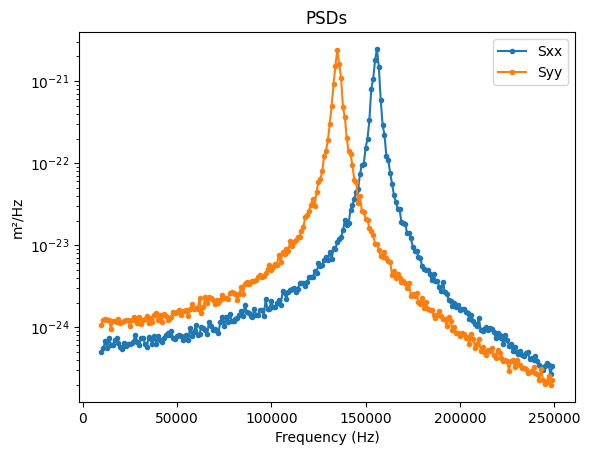

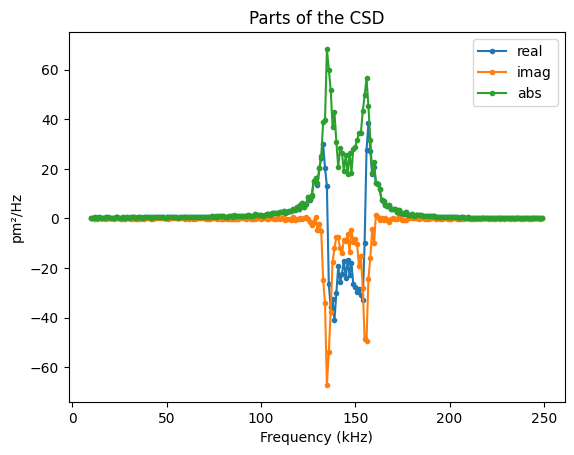

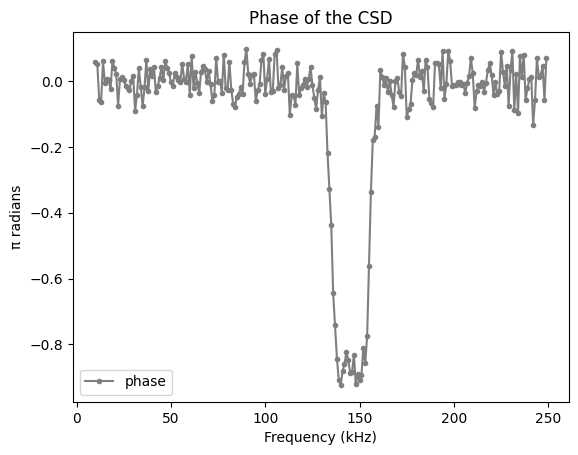

SpectralDensityEstimate(id=5867828304
    S_AB = S_xx
    type = PSD
    one_sided = True

    num_segments = 100
    num_segments_to_average = 100

    num_samples_per_segment = 10000
    len(freq_range) = 5000

    segment_time = 1.000 ms
    Δf = 1000.000 Hz

    averaging_time = 100.000 ms
    measurement_bandwidth = 10.000 Hz
    window = 1

    Var = Area = 10.976 nm²
    σ = √Area = 3.313 nm

    Afit = 1.737e-07 ± 2.772e-11 Hz²
    Ωfit = 155.783 ± 0.001 kHz
    Γfit = 2.893 ± 0.004 kHz

    temperature_via_area = 1.281 K

    type(source)=<class 'levisim.data.simulation.Simulation'>
    id(source)=5857610192
)
SpectralDensityEstimate(id=5861937680
    S_AB = S_yy
    type = PSD
    one_sided = True

    num_segments = 100
    num_segments_to_average = 100

    num_samples_per_segment = 10000
    len(freq_range) = 5000

    segment_time = 1.000 ms
    Δf = 1000.000 Hz

    averaging_time = 100.000 ms
    measurement_bandwidth = 10.000 Hz
    window = 1

    Var = Area = 11.552 

In [2]:
nseg = 100
Sxx = SpectralDensityEstimate(sim, 'xx', num_segments=nseg)
Syy = SpectralDensityEstimate(sim, 'yy', num_segments=nseg)
Sxy = SpectralDensityEstimate(sim, 'xy', num_segments=nseg)

# lower and upper bounds of the plots, in Hertz
lb, ub = 10e3, 250e3
ls = '.-'  # linestyle

# showing how to directly get at freqs, values from the Sxx, Syy objects
plt.plot(*Sxx.get_plot_points(lb, ub), ls, label='Sxx')
plt.plot(*Syy.get_plot_points(lb, ub), ls, label='Syy')
plt.title('PSDs')
plt.xlabel('Frequency (Hz)')
plt.ylabel('m²/Hz')
plt.legend()
plt.yscale('log')
plt.show()

# showing how to easily change axis units
freqs, csd = Sxy.get_plot_points(lb, ub)
freqs = freqs / kiloHz
csd = csd / pm**2

plt.plot(freqs, np.real(csd), ls, label='real')
plt.plot(freqs, np.imag(csd), ls, label='imag')
plt.plot(freqs, np.abs(csd), ls, label='abs')
plt.title('Parts of the CSD')
plt.xlabel('Frequency (kHz)')
plt.ylabel('pm²/Hz')
plt.legend()
plt.show()

plt.plot(freqs, np.angle(csd) / π, ls, color=grey, label='phase')
plt.title('Phase of the CSD')
plt.xlabel('Frequency (kHz)')
plt.ylabel('π radians')
plt.legend()
plt.show()

Sxx.info
Syy.info
Sxy.info